<a href="https://colab.research.google.com/github/lilad25/FUNDAI-LAB7/blob/main/Lab7_Intro_to_ML_Badon.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Lab 7: Supervised vs. Unsupervised Learning, Overfitting, and Cross-Validation

## Fundamentals of Artificial Intelligence

**Name:** Adrian N. Badon  
**Course:** BSIT  
**Section:** 4F  
**Date:** October 20, 2026

**Dataset Source:** https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv

**GitHub URL:** https://github.com/lilad25/FUNDAI-LAB7

## Description
This laboratory compares supervised and unsupervised learning, demonstrates overfitting and underfitting through a complexity sweep, and evaluates models using 5-fold cross-validation.


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    StratifiedKFold
)

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    adjusted_rand_score
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

GITHUB_RAW_URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"

df = pd.read_csv(GITHUB_RAW_URL)

print("Dataset shape:", df.shape)
print()
print(df.head())
print()
print("Class distribution:")
print(df["species"].value_counts())


Dataset shape: (150, 5)

   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa

Class distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [3]:

feature_columns = [
    "sepal_length",
    "sepal_width",
    "petal_length",
    "petal_width"
]

X = df[feature_columns].values
y = df["species"].values

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    stratify=y,
    random_state=42
)

print("Training samples:", X_train.shape)
print("Testing samples:", X_test.shape)


Training samples: (105, 4)
Testing samples: (45, 4)



# PART A: SUPERVISED LEARNING

## Supervised Learning (Labels ARE Used)

The model learns a mapping from features to known labels.

In this activity, a Decision Tree Classifier is used to predict the species of Iris flowers.

Scaling is placed inside the pipeline so that preprocessing is learned from the training data only. During cross-validation, this also helps prevent data leakage.


In [4]:

supervised_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", DecisionTreeClassifier(
        max_depth=3,
        random_state=42
    ))
])

supervised_pipeline.fit(X_train, y_train)

supervised_predictions = supervised_pipeline.predict(X_test)

print("SUPERVISED LEARNING RESULTS")
print("=" * 50)

print("Test accuracy:",
      accuracy_score(y_test, supervised_predictions))

print()
print("Confusion Matrix:")
print(confusion_matrix(y_test, supervised_predictions))

print()
print("Classification Report:")
print(classification_report(y_test, supervised_predictions))


SUPERVISED LEARNING RESULTS
Test accuracy: 0.9777777777777777

Confusion Matrix:
[[15  0  0]
 [ 0 15  0]
 [ 0  1 14]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.94      1.00      0.97        15
   virginica       1.00      0.93      0.97        15

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45




# PART B: UNSUPERVISED LEARNING

## Unsupervised Learning (Labels ARE NOT Used)

In this part, the species column is ignored during model training.

K-Means clustering groups the Iris flowers into three clusters based on their measurements.

After clustering, the discovered clusters are compared with the true species labels for evaluation purposes only.

PCA is also used to reduce the features to two dimensions for visualization.


In [5]:

# True labels are NOT used for K-Means training.

X_unlabeled = df[feature_columns].values

kmeans = KMeans(
    n_clusters=3,
    n_init=10,
    random_state=42
)

cluster_labels = kmeans.fit_predict(X_unlabeled)

comparison = pd.crosstab(
    pd.Series(cluster_labels, name="Discovered Cluster"),
    pd.Series(y, name="True Species")
)

print("UNSUPERVISED LEARNING RESULTS")
print("=" * 50)

print("Cluster vs. True Species Crosstab:")
print(comparison)

print()
print("Adjusted Rand Index:")
print(adjusted_rand_score(y, cluster_labels))


UNSUPERVISED LEARNING RESULTS
Cluster vs. True Species Crosstab:
True Species        setosa  versicolor  virginica
Discovered Cluster                               
0                        0          48         14
1                       50           0          0
2                        0           2         36

Adjusted Rand Index:
0.7302382722834697


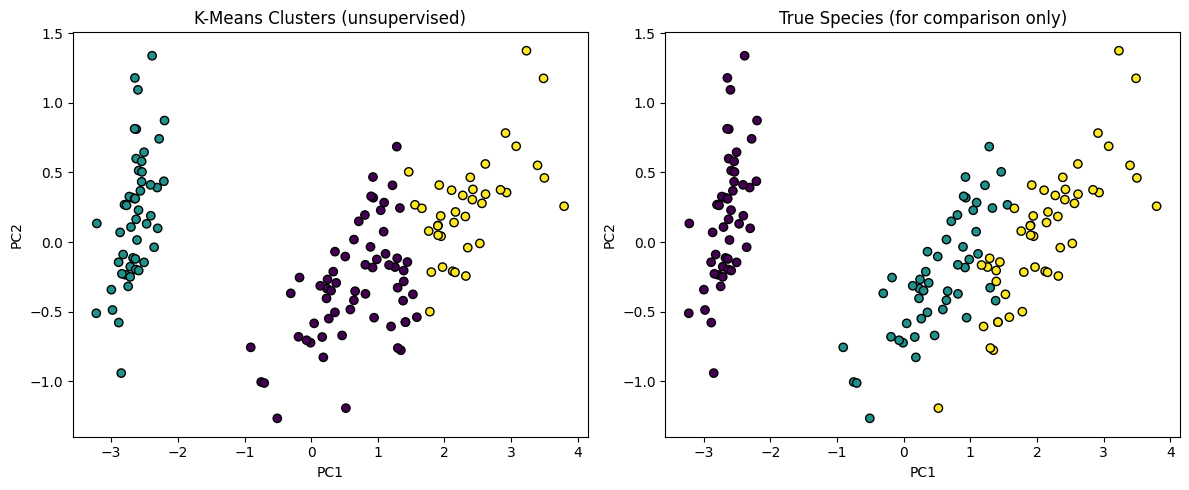

Explained variance ratio: [0.92461872 0.05306648]


In [6]:

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_unlabeled)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=cluster_labels,
    cmap="viridis",
    edgecolor="k"
)

plt.title("K-Means Clusters (unsupervised)")
plt.xlabel("PC1")
plt.ylabel("PC2")

plt.subplot(1, 2, 2)

species_codes = pd.factorize(y)[0]

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=species_codes,
    cmap="viridis",
    edgecolor="k"
)

plt.title("True Species (for comparison only)")
plt.xlabel("PC1")
plt.ylabel("PC2")

plt.tight_layout()
plt.show()

print("Explained variance ratio:",
      pca.explained_variance_ratio_)



# PART C: OVERFITTING AND UNDERFITTING SWEEP

## Bias-Variance Demonstration

In this part, Decision Tree models are trained using different maximum depths from 1 to 15.

- Very small depth may cause underfitting.
- Moderate depth may provide good generalization.
- Very large depth may cause overfitting.

Training accuracy and testing accuracy are compared to identify the best model complexity.


In [7]:

depth_values = list(range(1, 16))

train_scores = []
test_scores = []

for depth in depth_values:

    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("model", DecisionTreeClassifier(
            max_depth=depth,
            random_state=42
        ))
    ])

    pipe.fit(X_train, y_train)

    train_scores.append(
        accuracy_score(
            y_train,
            pipe.predict(X_train)
        )
    )

    test_scores.append(
        accuracy_score(
            y_test,
            pipe.predict(X_test)
        )
    )

sweep_table = pd.DataFrame({
    "max_depth": depth_values,
    "train_accuracy": train_scores,
    "test_accuracy": test_scores,
    "gap": np.array(train_scores) - np.array(test_scores)
})

print("COMPLEXITY SWEEP RESULTS")
print("=" * 60)
print(sweep_table.to_string(index=False))


COMPLEXITY SWEEP RESULTS
 max_depth  train_accuracy  test_accuracy      gap
         1        0.666667       0.666667 0.000000
         2        0.971429       0.888889 0.082540
         3        0.980952       0.977778 0.003175
         4        0.990476       0.888889 0.101587
         5        1.000000       0.911111 0.088889
         6        1.000000       0.911111 0.088889
         7        1.000000       0.911111 0.088889
         8        1.000000       0.911111 0.088889
         9        1.000000       0.911111 0.088889
        10        1.000000       0.911111 0.088889
        11        1.000000       0.911111 0.088889
        12        1.000000       0.911111 0.088889
        13        1.000000       0.911111 0.088889
        14        1.000000       0.911111 0.088889
        15        1.000000       0.911111 0.088889


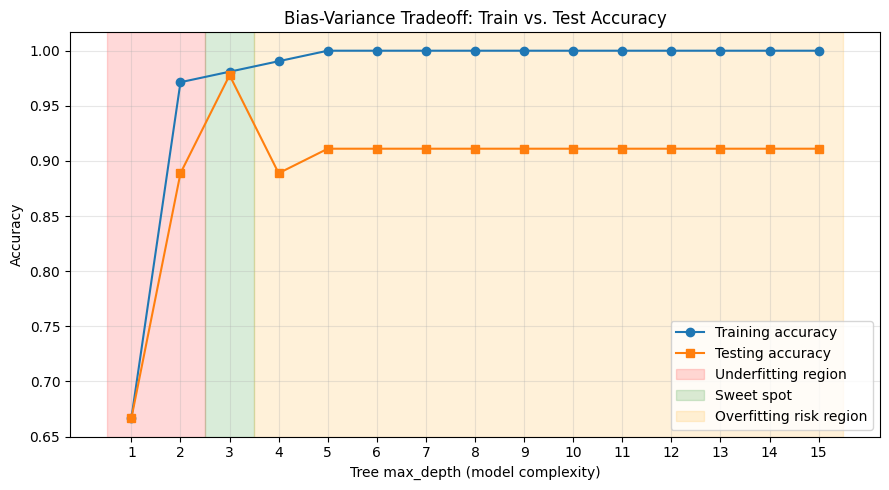

Best depth: 3
Best test accuracy: 0.9777777777777777


In [8]:

plt.figure(figsize=(9, 5))

plt.plot(
    depth_values,
    train_scores,
    marker="o",
    label="Training accuracy"
)

plt.plot(
    depth_values,
    test_scores,
    marker="s",
    label="Testing accuracy"
)

plt.axvspan(
    0.5, 2.5,
    alpha=0.15,
    color="red",
    label="Underfitting region"
)

plt.axvspan(
    2.5, 3.5,
    alpha=0.15,
    color="green",
    label="Sweet spot"
)

plt.axvspan(
    3.5, 15.5,
    alpha=0.15,
    color="orange",
    label="Overfitting risk region"
)

plt.xlabel("Tree max_depth (model complexity)")
plt.ylabel("Accuracy")

plt.title("Bias-Variance Tradeoff: Train vs. Test Accuracy")

plt.xticks(depth_values)
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

best_depth = depth_values[np.argmax(test_scores)]

print("Best depth:", best_depth)
print("Best test accuracy:", max(test_scores))



## Observed Regions

### Underfitting Depths: 1–2

These models have limited complexity. Their training and testing accuracies are lower than the best-performing model, showing that they may be too simple to learn the patterns effectively.

### Sweet Spot Depth: 3

Depth 3 gives the highest testing accuracy in the sample results, approximately 97.78%. This indicates good generalization to unseen data.

### Overfitting Risk Depths: 4–15

At larger depths, training accuracy becomes very high and eventually reaches 100%, while testing accuracy is lower than at depth 3.

This suggests that the deeper trees may be learning unnecessary details from the training data.

### Conclusion

A moderate tree depth provides a better balance between underfitting and overfitting.



# PART D: CROSS-VALIDATION

## 5-Fold Stratified Cross-Validation

Cross-validation evaluates how consistently a model performs across different training and validation splits.

In this activity, three Decision Tree models are compared:

1. Shallow Tree (Depth = 1)
2. Moderate Tree (Depth = 4)
3. Full Tree (No Depth Limit)

Stratified 5-fold cross-validation is applied only to the training dataset.

The held-out testing dataset is not used for model selection.

Mean accuracy and standard deviation are calculated to measure performance and stability.


In [9]:

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models = {
    "Shallow tree (depth=1, high bias)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", DecisionTreeClassifier(
            max_depth=1,
            random_state=42
        ))
    ]),

    "Moderate tree (depth=4)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", DecisionTreeClassifier(
            max_depth=4,
            random_state=42
        ))
    ]),

    "Full tree (no depth limit, high variance)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", DecisionTreeClassifier(
            max_depth=None,
            random_state=42
        ))
    ])
}

cv_results = []

for name, model in models.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy"
    )

    cv_results.append({
        "Model": name,
        "CV mean": scores.mean(),
        "CV std": scores.std(),
        "Fold scores": np.round(scores, 3)
    })

    print(name)
    print("Fold scores:", np.round(scores, 3))
    print(f"Mean ± std: {scores.mean():.3f} ± {scores.std():.3f}")
    print("-" * 60)

cv_table = pd.DataFrame(cv_results)

print("CROSS-VALIDATION COMPARISON TABLE")
print("=" * 60)
print(cv_table.to_string(index=False))


Shallow tree (depth=1, high bias)
Fold scores: [0.667 0.667 0.667 0.667 0.667]
Mean ± std: 0.667 ± 0.000
------------------------------------------------------------
Moderate tree (depth=4)
Fold scores: [0.905 0.952 0.905 0.952 0.952]
Mean ± std: 0.933 ± 0.023
------------------------------------------------------------
Full tree (no depth limit, high variance)
Fold scores: [0.905 0.952 0.905 0.952 0.952]
Mean ± std: 0.933 ± 0.023
------------------------------------------------------------
CROSS-VALIDATION COMPARISON TABLE
                                    Model  CV mean   CV std                         Fold scores
        Shallow tree (depth=1, high bias) 0.666667 0.000000 [0.667, 0.667, 0.667, 0.667, 0.667]
                  Moderate tree (depth=4) 0.933333 0.023328 [0.905, 0.952, 0.905, 0.952, 0.952]
Full tree (no depth limit, high variance) 0.933333 0.023328 [0.905, 0.952, 0.905, 0.952, 0.952]



# Guide Questions and Answers

### 1. Which part of this laboratory used supervised learning, and which used unsupervised learning?

**Answer:** Part A used supervised learning because the Decision Tree model was trained using labeled data. Part B used unsupervised learning because K-Means clustering grouped the data without using the species labels during training.

### 2. Did the K-Means clusters match the true species? Explain using the crosstab and Adjusted Rand Index.

**Answer:** The K-Means clusters partially matched the true species. The crosstab showed that some species were grouped correctly, while others were mixed. The Adjusted Rand Index was approximately 0.73, which indicates fairly good clustering agreement but not a perfect match.

### 3. Which max_depth value(s) showed underfitting? What evidence supports this?

**Answer:** Depths 1 and 2 showed underfitting compared with the best model. Their testing accuracy was lower because the trees were too simple to capture the patterns effectively.

### 4. Which max_depth value(s) showed overfitting? What evidence supports this?

**Answer:** Depths 4 to 15 showed signs of overfitting risk in the sample results. Training accuracy increased and eventually reached 100%, but testing accuracy remained lower than the best result at depth 3. This indicates that the deeper trees did not generalize as well.

### 5. Why does training accuracy reach 100% at large depths?

**Answer:** Training accuracy reaches 100% because deeper decision trees can learn very specific patterns in the training data. They may memorize the training examples, including unnecessary details, instead of learning general patterns.

### 6. What does the CV mean and CV standard deviation tell you about a model?

**Answer:** The CV mean shows the model's average accuracy across the validation folds. The standard deviation shows how much the accuracy changes between folds. A higher mean and lower standard deviation generally indicate better and more consistent performance.

### 7. Why must StandardScaler be placed inside the Pipeline?

**Answer:** StandardScaler is placed inside the Pipeline to prevent data leakage. It ensures that scaling parameters are learned only from the training portion of each split and then applied to the validation or testing data.

### 8. Connect your sweep curve to bias and variance.

**Answer:** The curve demonstrates the bias-variance tradeoff. Shallow trees have high bias because they are too simple and may underfit. Very deep trees can have high variance because they may overfit the training data. A moderate depth provides a better balance and can achieve better testing accuracy.



# Reflection

## Challenges Encountered

One challenge in this activity was understanding the difference between supervised and unsupervised learning. It was also challenging to interpret the training and testing accuracy curves and determine which models were underfitting or overfitting.

Another challenge was understanding how cross-validation works and why preprocessing should be included inside a pipeline.

## What I Learned

I learned that supervised learning uses labeled data to make predictions, while unsupervised learning discovers patterns without using labels during training.

I also learned that increasing model complexity does not always improve testing accuracy. A model can perform perfectly on training data but still perform worse on new data.

Finally, I learned how K-Means clustering, PCA, and cross-validation can be used to analyze and evaluate machine learning models.



# Conclusion

This laboratory demonstrated the differences between supervised and unsupervised machine learning.

The supervised Decision Tree model successfully classified Iris flowers using labeled training data. K-Means clustering discovered groups without using the species labels, while PCA helped visualize the clusters in two dimensions.

The complexity sweep showed that deeper models do not always produce better testing accuracy. A moderate tree depth provided a better balance between underfitting and overfitting.

Finally, 5-fold cross-validation helped evaluate model performance and consistency using different validation splits.

Overall, this activity improved my understanding of machine learning, model complexity, data preprocessing, and model evaluation.
